# CNN tự xây 7×7 — CIFAR-100
Giữ từng cell gốc, không gộp. Chỉ sửa trực tiếp nơi cần chia tập/lưu/nạp/hiển thị. CNN giữ nguyên kiến trúc Dense256 và augmentation gốc; ConvNeXt giữ Tiny/Linear(768,100). Chế độ TRAIN lưu mọi epoch; sau khi chọn thủ công, dùng LOAD ở phiên mới.


### Cấu hình TRAIN / LOAD — cell bổ sung


In [1]:
# Chỉ sửa các dòng cấu hình cần thiết. DATA_DIR giữ đúng đường dẫn ban đầu.
RUN_MODE = "TRAIN"                  # "TRAIN" hoặc "LOAD"
DATA_DIR = "/kaggle/input/datasets/fedesoriano/cifar100"
BUNDLE_PATH = ""                    # LOAD: ZIP phân tích/kho mọi epoch hoặc thư mục đã giải nén
OUTPUT_ROOT = "/kaggle/working/cifar100_unified"
SPLIT_SCHEME = "45k_5k_10k"          # Mặc định; lựa chọn khác: "50k_5k_5k"
SHARED_SPLIT_PATH = ""              # Tùy chọn: dùng chính split_indices.npz của notebook còn lại
SEED = 42
RUN_FULL_TSNE = True                # Toàn bộ Test; có thể tắt để xem nhanh các phần khác
RUN_DETAIL_TSNE = True              # Hình chi tiết các lớp bên dưới
TSNE_CLASS_IDS = list(range(10))
TSNE_PER_CLASS = 100                # Tự giảm nếu Test mỗi lớp có ít hơn 100 ảnh
TSNE_MAX_ITER = 1000
MODEL_KEY = "custom_cnn"
MODEL_NAME = "Custom CNN 7x7"
BEST_FILENAME = "best.keras"
INPUT_SIZE = 32
FEATURE_DIM = 256
BATCH_SIZE = 64
MAX_EPOCHS = 100
INITIAL_LR = 0.0003
USE_EARLY_STOPPING = True
LOSS_DESCRIPTION = "Sparse cross-entropy + L2(1e-4) on feature Dense kernel"


## 1. Import thư viện và đọc CIFAR-100


Train gốc: (50000, 32, 32, 3)
Test: (10000, 32, 32, 3)
Số lớp: 100


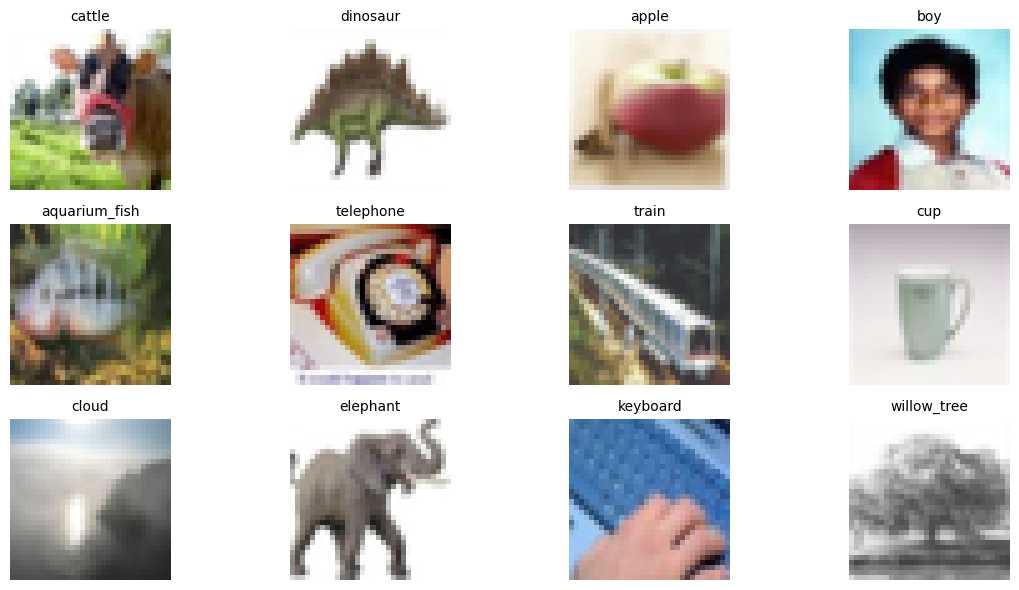

In [2]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
DATA_DIR = "/kaggle/input/datasets/fedesoriano/cifar100"
OUT_DIR = "/kaggle/working"
MODEL_PATH = os.path.join(OUT_DIR, "best_cifar100_cnn_v3.keras")
os.makedirs(OUT_DIR, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

def load_cifar_file(filename):
    with open(os.path.join(DATA_DIR, filename), "rb") as file:
        return pickle.load(file, encoding="bytes")

train_data = load_cifar_file("train")
test_data = load_cifar_file("test")
meta_data = load_cifar_file("meta")

x_train = train_data[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
y_train = np.array(train_data[b"fine_labels"])
x_test = test_data[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
y_test = np.array(test_data[b"fine_labels"])
class_names = [name.decode("utf-8") for name in meta_data[b"fine_label_names"]]

print("Train gốc:", x_train.shape)
print("Test:", x_test.shape)
print("Số lớp:", len(class_names))

plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]], fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

### Thư viện phụ trợ cho lưu và nạp — không đổi cách khởi tạo thiết bị


In [3]:
import os
import json
import pickle
import time
import random
import shutil
import hashlib
import inspect
import platform
import uuid
import zipfile
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata as package_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex, ListedColormap, BoundaryNorm
from matplotlib.ticker import MaxNLocator
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

try:
    from IPython.display import display, FileLink
except ImportError:
    def display(value):
        print(value.to_string(index=False) if isinstance(value, pd.DataFrame) else value)
    FileLink = None

SCHEMA_VERSION = "cifar100_unified_v1"
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.titlesize": 13, "axes.labelsize": 11,
                     "figure.dpi": 110, "savefig.dpi": 300})


In [4]:
import tensorflow as tf
EVALUATION_DEVICE = ", ".join(d.name for d in tf.config.list_physical_devices("GPU")) or "CPU"


In [5]:
def backend_details():
    return {"framework": "TensorFlow/Keras", "tensorflow_version": tf.__version__,
            "train_device": EVALUATION_DEVICE,
            "training": {"max_epochs": MAX_EPOCHS, "learning_rate": INITIAL_LR,
                         "early_stopping": USE_EARLY_STOPPING, "patience": 12, "min_delta": 0.001},
            "preprocessing": {"input_size": 32, "divide_by_255": True,
                              "train_augmentation": ["horizontal_flip", "translation_0.08", "rotation_0.03"]},
            "architecture_id": "cnn_v3_original_dense256"}


### Ghi cấu hình JSON


In [6]:
def json_write(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


In [7]:
def json_read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


### Kiểm tra tệp và phiên bản


In [8]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


In [9]:
def installed_version(name):
    try:
        return package_metadata.version(name)
    except package_metadata.PackageNotFoundError:
        return "unknown"


In [10]:
def file_links(paths):
    for path in map(Path, paths):
        if not path.is_file():
            continue
        print(f"{path.name}: {path.stat().st_size / (1024 ** 2):.2f} MiB")
        if FileLink is not None:
            display(FileLink(str(path)))
        else:
            print(path)


### Chia tập phân tầng


In [11]:
def stratified_split(labels, validation_fraction, seed):
    rng = np.random.default_rng(seed)
    train, validation = [], []
    for class_id in np.unique(labels):
        ids = rng.permutation(np.flatnonzero(labels == class_id))
        if len(ids) < 2:
            raise ValueError("Mỗi lớp cần ít nhất 2 ảnh để tách Train và Validation.")
        n_validation = min(len(ids) - 1, max(1, int(round(len(ids) * validation_fraction))))
        validation.extend(ids[:n_validation].tolist())
        train.extend(ids[n_validation:].tolist())
    train, validation = np.asarray(train, dtype=np.int64), np.asarray(validation, dtype=np.int64)
    rng.shuffle(train)
    rng.shuffle(validation)
    return train, validation


In [12]:
def create_splits(labels, original_train_count, scheme, seed):
    if scheme == "45k_5k_10k":
        train, validation = stratified_split(labels[:original_train_count], 0.1, seed)
        test = np.arange(original_train_count, len(labels), dtype=np.int64)
    elif scheme == "50k_5k_5k":
        validation_local, test_local = stratified_split(labels[original_train_count:], 0.5, seed)
        train = np.arange(original_train_count, dtype=np.int64)
        validation = validation_local + original_train_count
        test = test_local + original_train_count
    else:
        raise ValueError("SPLIT_SCHEME phải là '45k_5k_10k' hoặc '50k_5k_5k'.")
    return {"train_idx": train, "val_idx": validation, "test_idx": test}


In [13]:
def validate_splits(splits, count):
    arrays = [np.asarray(splits[key], dtype=np.int64) for key in ("train_idx", "val_idx", "test_idx")]
    joined = np.concatenate(arrays)
    if any(len(array) == 0 for array in arrays):
        raise ValueError("Train/Validation/Test không được rỗng.")
    if np.any(joined < 0) or np.any(joined >= count) or len(np.unique(joined)) != len(joined):
        raise ValueError("Chỉ số chia tập không hợp lệ hoặc có ảnh trùng giữa các tập.")
    if len(joined) != count:
        raise ValueError("Danh sách chia tập chưa bao phủ toàn bộ dữ liệu.")


### Nhận diện danh sách ảnh và lần chạy


In [14]:
def split_signature(splits, dataset_digest):
    digest = hashlib.sha256(dataset_digest.encode("ascii"))
    for key in ("train_idx", "val_idx", "test_idx"):
        digest.update(key.encode("ascii"))
        digest.update(np.asarray(splits[key], dtype="<i8").tobytes())
    return digest.hexdigest()


In [15]:
def new_run_directory(prefix):
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    directory = Path(OUTPUT_ROOT) / f"{prefix}_{stamp}_{uuid.uuid4().hex[:6]}"
    directory.mkdir(parents=True, exist_ok=False)
    return directory


In [16]:
def visual_indices(labels, test_idx, seed):
    rng = np.random.default_rng(seed)
    test_labels = labels[test_idx]
    details = []
    for class_id in TSNE_CLASS_IDS:
        positions = np.flatnonzero(test_labels == class_id)
        if len(positions):
            details.extend(rng.choice(positions, size=min(TSNE_PER_CLASS, len(positions)), replace=False).tolist())
    predictions = rng.choice(len(test_idx), size=min(30, len(test_idx)), replace=False)
    return {"prediction_positions": np.asarray(predictions, dtype=np.int64),
            "tsne_detail_positions": np.asarray(details, dtype=np.int64),
            "feature_map_position": np.asarray(0, dtype=np.int64)}


### Đọc bộ tệp đã tải lên


In [17]:
def resolve_bundle(source, destination):
    source = Path(source).expanduser()
    if not source.exists():
        raise FileNotFoundError(f"Không tìm thấy BUNDLE_PATH: {source}")
    if source.is_file():
        if source.suffix.lower() != ".zip":
            raise ValueError("BUNDLE_PATH cần trỏ tới ZIP phân tích hoặc thư mục đã giải nén, không chỉ riêng tệp trọng số.")
        extracted = destination / "_bundle_input"
        extracted.mkdir()
        with zipfile.ZipFile(source) as archive:
            for item in archive.infolist():
                target = (extracted / item.filename).resolve()
                if not target.is_relative_to(extracted.resolve()):
                    raise ValueError("ZIP chứa đường dẫn nằm ngoài thư mục giải nén.")
            archive.extractall(extracted)
        source = extracted
    candidates = list(source.rglob("config.json"))
    if len(candidates) != 1:
        raise ValueError("Thư mục/ZIP phải chứa đúng một config.json của một lần chạy.")
    return candidates[0].parent


In [18]:
mode = RUN_MODE.upper()
if mode not in ("TRAIN", "LOAD"):
    raise ValueError("RUN_MODE chỉ nhận TRAIN hoặc LOAD.")
run_dir = new_run_directory(MODEL_KEY if mode == "TRAIN" else MODEL_KEY + "_loaded")
ANALYSIS_READY = False
analysis_dir = None
selected_info = None
history_df = pd.DataFrame()
if mode == "TRAIN":
    checkpoint_root = run_dir / "checkpoints"
    checkpoint_root.mkdir()
else:
    if not BUNDLE_PATH:
        raise ValueError("LOAD cần điền BUNDLE_PATH; không tự train lại khi thiếu mô hình.")
    bundle_source = resolve_bundle(BUNDLE_PATH, run_dir)
    for name in ("config.json", "history.csv", "split_indices.npz", "visual_indices.npz"):
        if not (bundle_source / name).is_file():
            raise FileNotFoundError(f"Thiếu {name} trong bộ tệp đã tải lên.")
        shutil.copy2(bundle_source / name, run_dir / name)
    run_config = json_read(run_dir / "config.json")
    if run_config.get("model_key") != MODEL_KEY or run_config.get("schema_version") != SCHEMA_VERSION:
        raise ValueError("Bộ tệp không đúng mô hình/phiên bản notebook.")
    if run_config["feature_dim"] != FEATURE_DIM or run_config["input_size"] != INPUT_SIZE:
        raise ValueError("Checkpoint khác kiến trúc gốc: CNN 256D/32x32, ConvNeXt 768D/224x224.")
    history_df = pd.read_csv(run_dir / "history.csv")
    checkpoint_root = bundle_source / "checkpoints"
    if (bundle_source / BEST_FILENAME).is_file() and (bundle_source / "selection.json").is_file():
        for name in (BEST_FILENAME, "selection.json"):
            shutil.copy2(bundle_source / name, run_dir / name)
        selected_info = json_read(run_dir / "selection.json")
        if sha256_file(run_dir / BEST_FILENAME) != selected_info["checkpoint_sha256"]:
            raise ValueError("Checkpoint không khớp selection.json.")
    elif not checkpoint_root.is_dir():
        raise FileNotFoundError("Thiếu best/selection.json hoặc kho checkpoints.")
print("Kết quả:", run_dir)


Kết quả: /kaggle/working/cifar100_unified/custom_cnn_20261023T122647Z_069cda


## 2. Chia Train / Validation / Test và chuẩn hóa ảnh
Phân tầng theo nhãn, mặc định 45.000/5.000/10.000. LOAD dùng lại chính danh sách đã lưu.


In [19]:
# Dùng ảnh gốc của các cell đọc dữ liệu, không thay đường dẫn dataset.
raw_images = np.ascontiguousarray(np.concatenate([x_train, x_test], axis=0))
raw_labels = np.concatenate([np.asarray(y_train, dtype=np.int64), np.asarray(y_test, dtype=np.int64)])
original_train_count = len(x_train)
digest = hashlib.sha256()
digest.update(memoryview(raw_images))
digest.update(raw_labels.astype("<i8").tobytes())
digest.update(json.dumps(class_names, ensure_ascii=False).encode("utf-8"))
dataset_digest = digest.hexdigest()
if mode == "TRAIN":
    if SHARED_SPLIT_PATH:
        with np.load(SHARED_SPLIT_PATH, allow_pickle=False) as saved:
            if str(saved["dataset_sha256"].item()) != dataset_digest or str(saved["split_scheme"].item()) != SPLIT_SCHEME:
                raise ValueError("Tệp chia tập dùng chung không khớp dataset/cách chia.")
            splits = {key:saved[key].astype(np.int64) for key in ("train_idx","val_idx","test_idx")}
    else:
        splits = create_splits(raw_labels, original_train_count, SPLIT_SCHEME, SEED)
    validate_splits(splits, len(raw_labels))
    np.savez_compressed(run_dir / "split_indices.npz", **splits,
                        dataset_sha256=np.asarray(dataset_digest), split_scheme=np.asarray(SPLIT_SCHEME))
    visual_samples = visual_indices(raw_labels, splits["test_idx"], SEED)
    np.savez_compressed(run_dir / "visual_indices.npz", **visual_samples)
else:
    if run_config["dataset_sha256"] != dataset_digest or run_config["class_names"] != class_names:
        raise ValueError("Dataset hoặc thứ tự tên lớp khác lần train.")
    with np.load(run_dir / "split_indices.npz", allow_pickle=False) as saved:
        splits = {key:saved[key].astype(np.int64) for key in ("train_idx","val_idx","test_idx")}
    validate_splits(splits, len(raw_labels))
    if split_signature(splits, dataset_digest) != run_config["split_signature"]:
        raise ValueError("Danh sách chia tập khác config.json.")
    with np.load(run_dir / "visual_indices.npz", allow_pickle=False) as saved:
        visual_samples = {key:saved[key] for key in saved.files}
display(pd.DataFrame([{"Split":label,"Images":len(splits[key])}
                      for label,key in [("Train","train_idx"),("Validation","val_idx"),("Test","test_idx")]]))
file_links([run_dir / "split_indices.npz"])


,Split,Images
0,Train,45000
1,Validation,5000
2,Test,10000


split_indices.npz: 0.15 MiB


/kaggle/working/cifar100_unified/custom_cnn_20261023T122647Z_069cda/split_indices.npz

In [20]:
if mode == "TRAIN":
    run_config = {"schema_version":SCHEMA_VERSION,"model_key":MODEL_KEY,"model_name":MODEL_NAME,
                  "seed":SEED,"split_scheme":SPLIT_SCHEME,"dataset_sha256":dataset_digest,
                  "split_signature":split_signature(splits,dataset_digest),"data_dir":DATA_DIR,
                  "class_names":class_names,"num_classes":len(class_names),"feature_dim":FEATURE_DIM,
                  "input_size":INPUT_SIZE,"batch_size":BATCH_SIZE,"loss_definition":LOSS_DESCRIPTION,
                  "run_id":run_dir.name,"python":platform.python_version(),
                  "visualization":{"tsne_class_ids":TSNE_CLASS_IDS,"tsne_per_class":TSNE_PER_CLASS,
                                   "seed":SEED,"perplexity":30,"learning_rate":200,"max_iter":TSNE_MAX_ITER},
                  **backend_details()}
    json_write(run_dir / "config.json",run_config)
pd.DataFrame({"class_id":np.arange(len(class_names)),"class_name":class_names}).to_csv(run_dir / "class_names.csv",index=False)


In [21]:
X_train = raw_images[splits["train_idx"]].astype("float32") / 255.0
Y_train = raw_labels[splits["train_idx"]]
X_val = raw_images[splits["val_idx"]].astype("float32") / 255.0
Y_val = raw_labels[splits["val_idx"]]
X_test = raw_images[splits["test_idx"]].astype("float32") / 255.0
Y_test = raw_labels[splits["test_idx"]]
print("DATA READY!",X_train.shape,X_val.shape,X_test.shape)


DATA READY! (45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


## 3. Tạo mô hình CNN V3 (Conv1 = 7×7)
**Giữ nguyên kiến trúc V3 gốc:** Conv1 32 bộ lọc 7×7, các lớp Conv kế tiếp 64/128/128/256/256, Dense 256, BatchNorm, Dropout và augmentation.


In [22]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

tf.keras.utils.set_random_seed(42)

L2 = regularizers.l2(1e-4)

augmentation_v3 = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomRotation(0.03),
    layers.RandomContrast(0.1),
], name="augmentation_v3")


model_v3 = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    augmentation_v3,

    # Block 1 - First Conv 7x7
    layers.Conv2D(
        32, (7, 7), padding="same",
        use_bias=False, name="conv1"
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(
        64, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),

    # Block 2
    layers.Conv2D(
        128, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(
        128, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),
    layers.Dropout(0.2),

    # Block 3
    layers.Conv2D(
        256, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(
        256, (3, 3), padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(2),
    layers.Dropout(0.3),

    # Classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=L2
    ),
    layers.Dropout(0.4),

    layers.Dense(
        100,
        activation="softmax"
    )
])

model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v3.summary()

I0000 00:00:1792758409.719557      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792758409.723618      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation_v3 (Sequential)    │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │         4,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 256)      │             

 Total params: 1,224,004 (4.67 MB)

 Trainable params: 1,222,276 (4.66 MB)

 Non-trainable params: 1,728 (6.75 KB)

## 4. Huấn luyện CNN V3
Giữ LR/batch/EarlyStopping gốc; lưu riêng mọi epoch đã chạy.


### Ghi lịch sử mỗi epoch


In [23]:
def append_history(row):
    global history_df
    if not all(np.isfinite(row[key]) for key in ("train_loss", "val_loss", "train_accuracy", "val_accuracy")):
        raise ValueError("Loss/Accuracy không hữu hạn; dừng để không chọn checkpoint lỗi.")
    history_df = pd.concat([history_df, pd.DataFrame([row])], ignore_index=True)
    temporary = run_dir / "history.csv.tmp"
    history_df.to_csv(temporary, index=False)
    temporary.replace(run_dir / "history.csv")


In [24]:
class RecordEpochHistory(tf.keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.lr = float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
    def on_epoch_end(self, epoch, logs=None):
        values = logs or {}
        append_history({"epoch":epoch+1,"phase":"scratch","phase_epoch":epoch+1,"learning_rate":self.lr,
                        "train_loss":float(values["loss"]),"train_accuracy":float(values["accuracy"]),
                        "val_loss":float(values["val_loss"]),"val_accuracy":float(values["val_accuracy"]),
                        "checkpoint":f"epoch_{epoch+1:03d}.keras"})


In [25]:
if mode == "TRAIN":
    if (run_dir / "history.csv").exists():
        raise RuntimeError("Lần chạy này đã có lịch sử; không chạy lại cell train. Muốn train mới, chạy lại từ đầu.")
    callbacks_v3 = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=18,
            min_delta=0.0005,
            verbose=1,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6
        ),

        tf.keras.callbacks.ModelCheckpoint(
            str(checkpoint_root / "epoch_{epoch:03d}.keras"),
            monitor="val_loss",
            save_best_only=False
        )
    ]

    if not USE_EARLY_STOPPING:
        callbacks_v3 = [callback for callback in callbacks_v3 if not isinstance(callback, tf.keras.callbacks.EarlyStopping)]
    # Lưu trọng số epoch trước khi EarlyStopping có thể khôi phục trọng số cũ.
    callbacks_v3 = [callback for callback in callbacks_v3 if isinstance(callback, tf.keras.callbacks.ModelCheckpoint)] + [callback for callback in callbacks_v3 if not isinstance(callback, tf.keras.callbacks.ModelCheckpoint)]
    model_v3.optimizer.learning_rate.assign(INITIAL_LR)

    history_v3 = model_v3.fit(
        X_train,
        Y_train,
        validation_data=(X_val, Y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks_v3 + [RecordEpochHistory()],
        verbose=1
    )
else:
    print("LOAD: bỏ qua huấn luyện.")


Epoch 1/100


E0000 00:00:1792758416.640528      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 29ms/step - accuracy: 0.0878 - loss: 4.0516 - val_accuracy: 0.0790 - val_loss: 4.1573 - learning_rate: 3.0000e-04
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.1630 - loss: 3.5152 - val_accuracy: 0.1466 - val_loss: 3.6143 - learning_rate: 3.0000e-04
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.2200 - loss: 3.1910 - val_accuracy: 0.2250 - val_loss: 3.1255 - learning_rate: 3.0000e-04
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.2585 - loss: 2.9586 - val_accuracy: 0.2476 - val_loss: 3.0419 - learning_rate: 3.0000e-04
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - accuracy: 0.2933 - loss: 2.7801 - val_accuracy: 0.3032 - val_loss: 2.7464 - learning_rate: 3.0000e-04
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.3235 - loss: 2.6396 - val_accuracy: 0.2238 - val_loss: 3.3723 - learning_rate: 3.0000e-04
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - a

## 5. Lưu lịch sử và vẽ Accuracy / Loss


### Lưu hình và ghi checkpoint trên hình


In [26]:
def checkpoint_caption():
    return f"{MODEL_NAME} | epoch {int(selected_info['epoch'])} | {selected_info['phase']}"


In [27]:
def save_figure(fig, name, target=None):
    destination = Path(target or analysis_dir) / name
    fig.savefig(destination, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return destination


Các mốc tham khảo, không tự chọn thay bạn:


,Criterion,Epoch,Phase,Val Loss,Val Accuracy (%)
0,Minimum validation loss,68,scratch,1.4714,60.64
1,Maximum validation accuracy,81,scratch,1.4720,60.94


Tổng số epoch thực tế: 86. Accuracy trong bảng dưới tính bằng %.


,epoch,phase,phase_epoch,learning_rate,train_loss,train_accuracy,val_loss,val_accuracy,checkpoint
0,1,scratch,1,0.0003,4.05165,8.77556,4.15729,7.90,epoch_001.keras
1,2,scratch,2,0.0003,3.51522,16.30444,3.61430,14.66,epoch_002.keras
2,3,scratch,3,0.0003,3.19095,22.00000,3.12551,22.50,epoch_003.keras
3,4,scratch,4,0.0003,2.95861,25.84667,3.04189,24.76,epoch_004.keras
4,5,scratch,5,0.0003,2.78014,29.32667,2.74642,30.32,epoch_005.keras
...,...,...,...,...,...,...,...,...,...
81,82,scratch,82,0.0000,1.12904,67.52889,1.47514,60.92,epoch_082.keras
82,83,scratch,83,0.0000,1.13014,67.38889,1.47537,60.72,epoch_083.keras
83,84,scratch,84,0.0000,1.12866,67.59111,1.47750,60.64,epoch_084.keras
84,85,scratch,85,0.0000,1.12867,67.55334,1.47790,60.84,epoch_085.keras


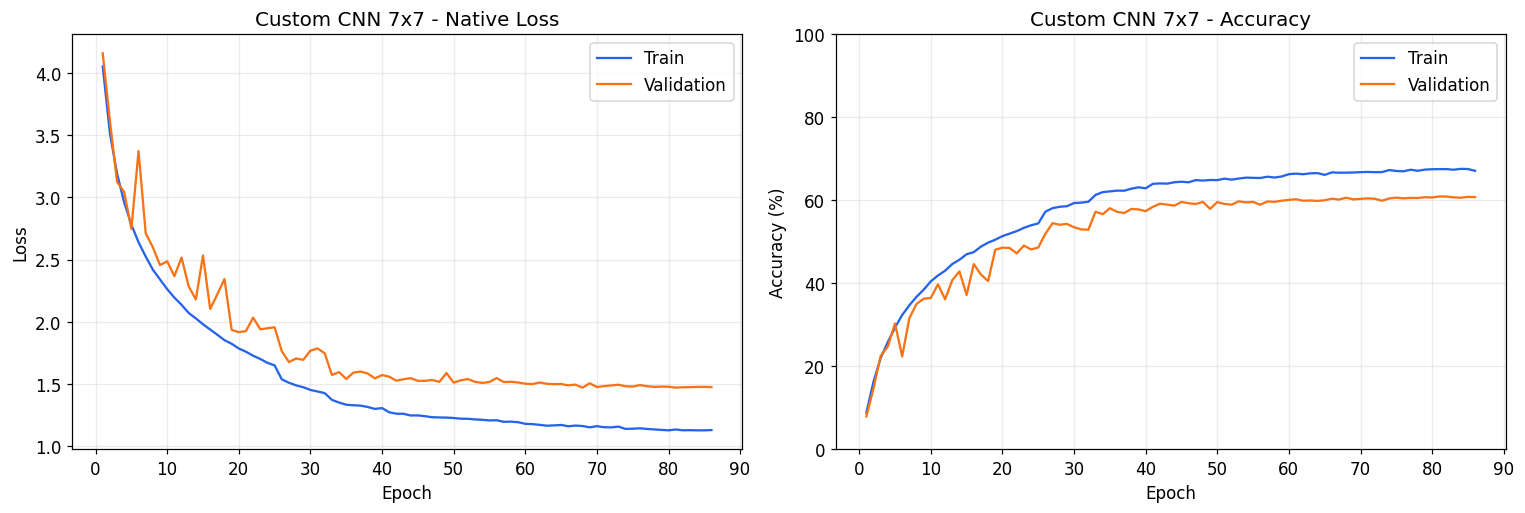

In [28]:
if not history_df.empty:
    selected_epoch = selected_info["epoch"] if selected_info else None
    frame = pd.read_csv(run_dir / "history.csv") if (run_dir / "history.csv").is_file() else history_df

    candidates = []

    for criterion, index in (("Minimum validation loss", frame["val_loss"].idxmin()),
                             ("Maximum validation accuracy", frame["val_accuracy"].idxmax())):
        row = frame.loc[index]
        candidates.append({"Criterion": criterion, "Epoch": int(row["epoch"]), "Phase": row["phase"],
                           "Val Loss": row["val_loss"], "Val Accuracy (%)": row["val_accuracy"] * 100})

    print("Các mốc tham khảo, không tự chọn thay bạn:")

    display(pd.DataFrame(candidates).round(4))

    table = frame.copy()

    table["train_accuracy"] *= 100

    table["val_accuracy"] *= 100

    print(f"Tổng số epoch thực tế: {len(frame)}. Accuracy trong bảng dưới tính bằng %.")

    display(table.round(5))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

    axes[0].plot(frame["epoch"], frame["train_loss"], color="#2563eb", label="Train")

    axes[0].plot(frame["epoch"], frame["val_loss"], color="#f97316", label="Validation")

    axes[0].set(title=f"{MODEL_NAME} - Native Loss", xlabel="Epoch", ylabel="Loss")

    axes[1].plot(frame["epoch"], frame["train_accuracy"] * 100, color="#2563eb", label="Train")

    axes[1].plot(frame["epoch"], frame["val_accuracy"] * 100, color="#f97316", label="Validation")

    axes[1].set(title=f"{MODEL_NAME} - Accuracy", xlabel="Epoch", ylabel="Accuracy (%)")

    axes[1].set_ylim(0, 100)

    changes = frame.loc[frame["phase"].ne(frame["phase"].shift())].iloc[1:]

    for ax in axes:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        for _, row in changes.iterrows():
            ax.axvline(float(row["epoch"]) - 0.5, color="gray", linestyle="--", label="Start fine-tuning")
        if selected_epoch is not None:
            ax.axvline(int(selected_epoch), color="#7c3aed", linestyle=":", linewidth=2, label=f"Selected: {selected_epoch}")
        ax.grid(alpha=0.25)
        ax.legend()

    fig.tight_layout()

    save_figure(fig, "training_curves.png", target=analysis_dir if analysis_dir else run_dir)


### Chọn và nạp checkpoint epoch 50



In [42]:
SELECTED_EPOCH = 68
import hashlib

epoch_row = history_df.set_index("epoch").loc[SELECTED_EPOCH]
MODEL_PATH = checkpoint_root / epoch_row["checkpoint"]
selected_model = tf.keras.models.load_model(MODEL_PATH)

analysis_dir = run_dir / f"analysis_epoch_{SELECTED_EPOCH:03d}"
analysis_dir.mkdir(exist_ok=True)
checkpoint_sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()

## 6. Đánh giá checkpoint đã chọn trên Train / Validation / Test


In [43]:
from sklearn.metrics import precision_recall_fscore_support

rows = []
for name, x, y in [
    ("Train Evaluation", X_train, Y_train),
    ("Validation", X_val, Y_val),
    ("Test", X_test, Y_test)
]:
    metrics = selected_model.evaluate(
        x, y, batch_size=BATCH_SIZE, verbose=0, return_dict=True
    )
    probabilities = selected_model.predict(x, batch_size=BATCH_SIZE, verbose=0)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y, probabilities.argmax(1), labels=np.arange(len(class_names)),
        average="macro", zero_division=0
    )
    rows.append({
        "Split": name, "Native Loss": metrics["loss"],
        "Accuracy (%)": metrics["accuracy"] * 100,
        "Macro Precision (%)": precision * 100,
        "Macro Recall (%)": recall * 100, "Macro F1 (%)": f1 * 100
    })
    if name == "Test":
        test_probabilities = probabilities

evaluation_table = pd.DataFrame(rows)
evaluation_table.to_csv(analysis_dir / "evaluation.csv", index=False)

np.savez_compressed(
    analysis_dir / "test_predictions.npz",
    probabilities=test_probabilities, true_labels=Y_test,
    predicted_labels=test_probabilities.argmax(1),
    global_indices=splits["test_idx"], checkpoint_sha256=checkpoint_sha256
)
display(evaluation_table.round(4))

,Split,Native Loss,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%)
0,Train Evaluation,0.9296,73.2133,74.1851,73.2133,73.0586
1,Validation,1.4714,60.6400,61.9695,60.6400,60.3855
2,Test,1.5014,59.8400,61.1658,59.8400,59.7017


## 7. Visualize **32 bộ lọc Conv1 7×7**
Conv1 có tensor trọng số `(7, 7, 3, 32)`. Mỗi filter có ba kênh RGB nên có thể hiển thị như một ảnh màu nhỏ.


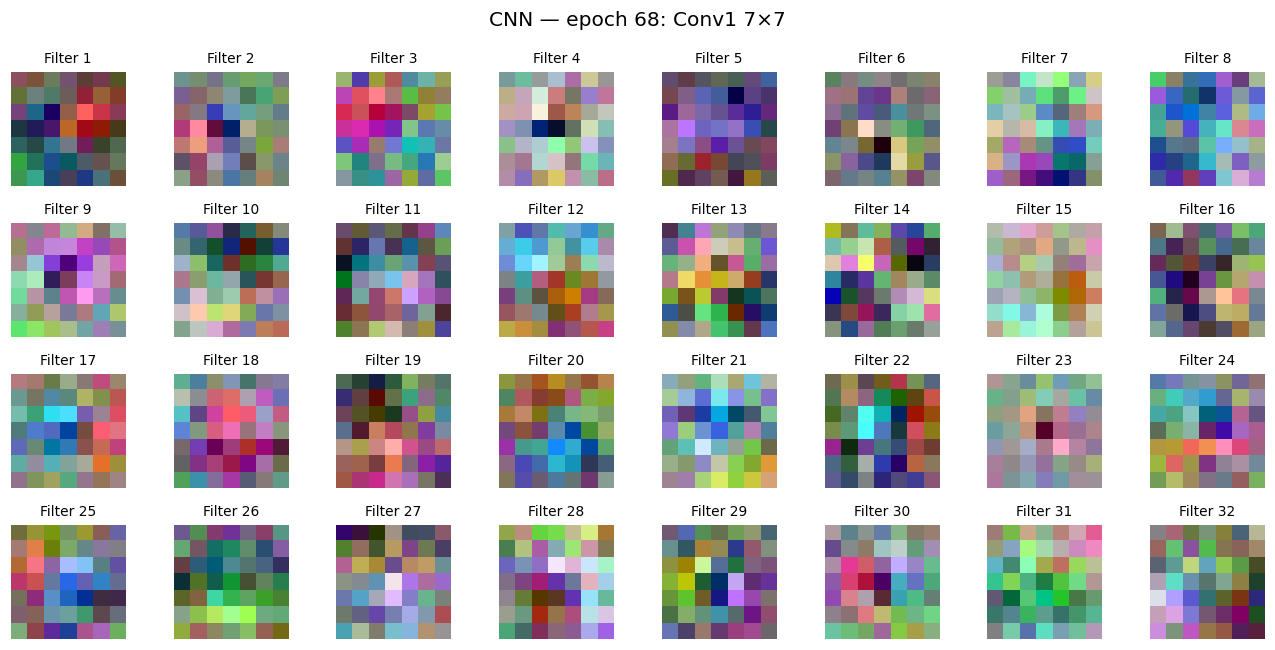

In [44]:
weights = selected_model.get_layer("conv1").get_weights()[0]
fig, axes = plt.subplots(4, 8, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    kernel = weights[:, :, :, i]
    kernel = (kernel - kernel.min()) / (kernel.max() - kernel.min() + 1e-8)
    ax.imshow(kernel)
    ax.set_title(f"Filter {i + 1}", fontsize=9)
    ax.axis("off")

fig.suptitle(f"CNN — epoch {SELECTED_EPOCH}: Conv1 7×7")
fig.tight_layout()
fig.savefig(analysis_dir / "conv1_filters.png", dpi=200)
plt.show()
plt.close(fig)

## 8. Feature maps từ tầng nông đến tầng sâu


### Feature maps: tầng nông → giữa → sâu


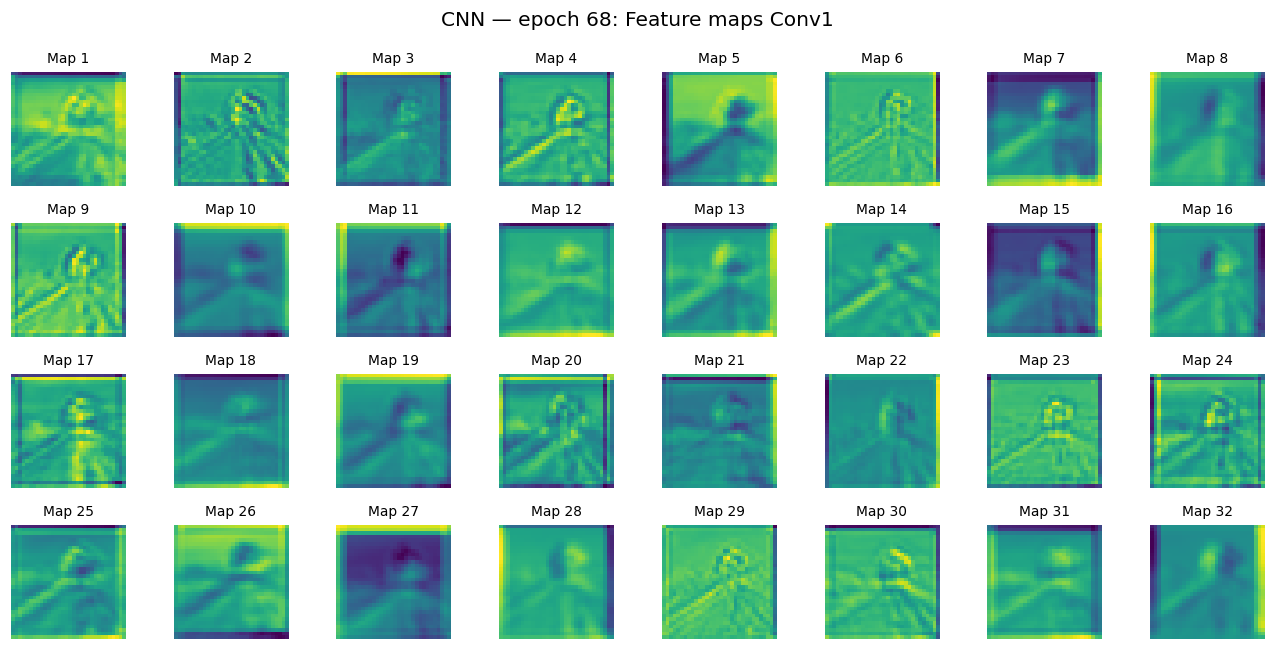

In [45]:
for name in ("feature_maps_middle_conv3.png", "feature_maps_deep_conv6.png"):
    (analysis_dir / name).unlink(missing_ok=True)

map_model = tf.keras.Model(
    selected_model.inputs[0],
    selected_model.get_layer("conv1").output
)
position = int(visual_samples["feature_map_position"])
maps = map_model(X_test[position:position + 1], training=False).numpy()[0]

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(maps[:, :, i], cmap="viridis")
    ax.set_title(f"Map {i + 1}", fontsize=9)
    ax.axis("off")

fig.suptitle(f"CNN — epoch {SELECTED_EPOCH}: Feature maps Conv1")
fig.tight_layout()
fig.savefig(analysis_dir / "feature_maps_shallow_conv1.png", dpi=200)
plt.show()
plt.close(fig)

### Trích feature vector toàn bộ Test — CNN 256D; ConvNeXt 768D


In [46]:
feature_layer = next(
    layer for layer in selected_model.layers
    if isinstance(layer, layers.Dense) and layer.units == 256
)
feature_extractor = tf.keras.Model(
    selected_model.inputs[0], feature_layer.output
)
test_features = feature_extractor.predict(
    X_test, batch_size=BATCH_SIZE, verbose=0
)

np.savez_compressed(
    analysis_dir / "test_features.npz", features=test_features,
    labels=Y_test, global_indices=splits["test_idx"],
    checkpoint_sha256=checkpoint_sha256
)
test_features.shape

(10000, 256)

## 9. Feature Vector 256 chiều → t-SNE 2D toàn bộ Test và chi tiết 10 lớp



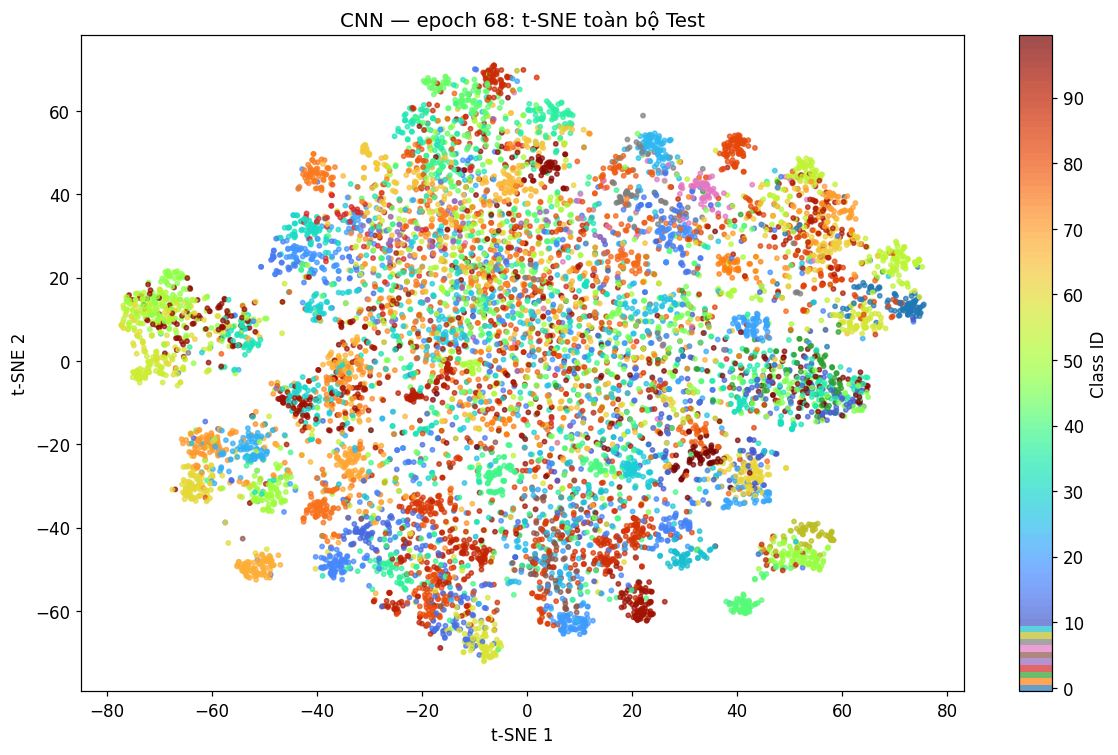

In [47]:
import inspect
from sklearn.manifold import TSNE
from matplotlib.colors import ListedColormap

colors = plt.get_cmap("turbo")(np.linspace(0, 1, len(class_names)))
colors[:10] = plt.get_cmap("tab10")(np.arange(10))

tsne_params = dict(
    n_components=2, perplexity=min(30, len(Y_test) - 1),
    learning_rate=200, init="pca", random_state=SEED
)
iteration_key = "max_iter" if "max_iter" in inspect.signature(TSNE).parameters else "n_iter"
tsne_params[iteration_key] = TSNE_MAX_ITER

projection = TSNE(**tsne_params).fit_transform(test_features)
np.savez_compressed(
    analysis_dir / "tsne_all_test.npz", coordinates=projection,
    labels=Y_test, global_indices=splits["test_idx"],
    checkpoint_sha256=checkpoint_sha256
)

fig, ax = plt.subplots(figsize=(11, 7))
scatter = ax.scatter(
    projection[:, 0], projection[:, 1], c=Y_test,
    cmap=ListedColormap(colors), vmin=-0.5,
    vmax=len(class_names) - 0.5, s=8, alpha=0.7
)
fig.colorbar(scatter, ax=ax, ticks=np.arange(0, len(class_names), 10), label="Class ID")
ax.set(title=f"CNN — epoch {SELECTED_EPOCH}: t-SNE toàn bộ Test",
       xlabel="t-SNE 1", ylabel="t-SNE 2")
fig.tight_layout()
fig.savefig(analysis_dir / "tsne_all_test.png", dpi=200)
plt.show()
plt.close(fig)

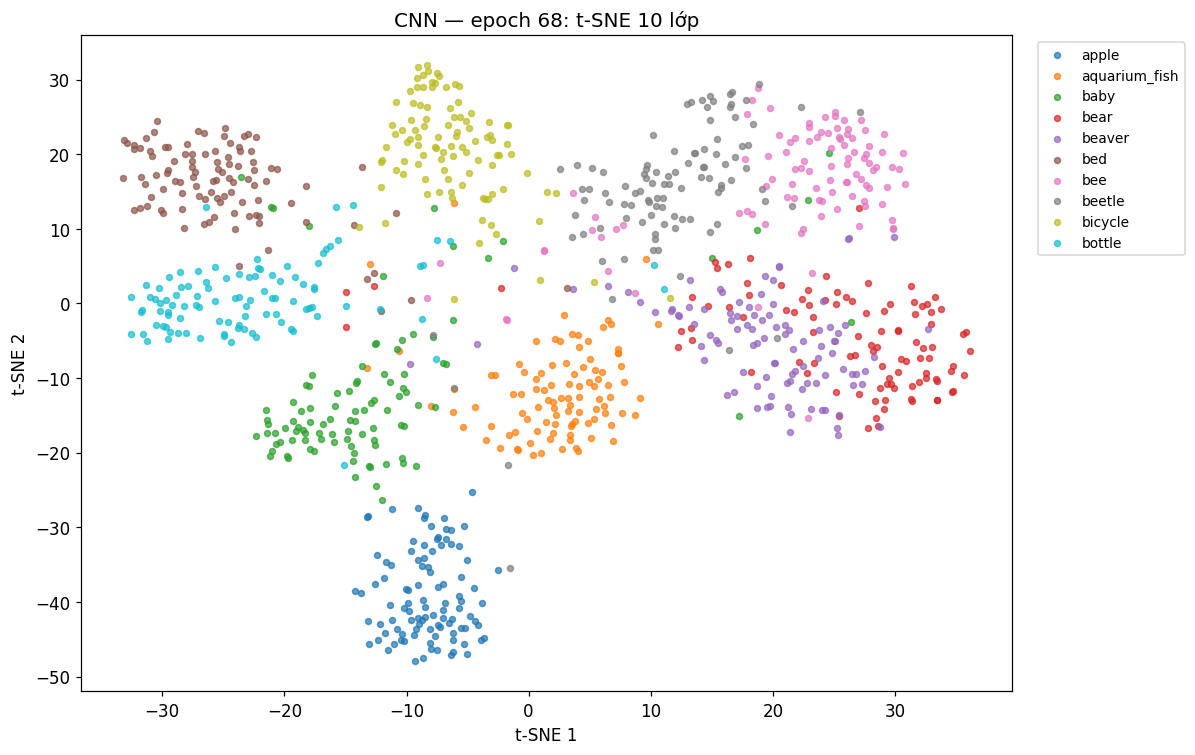

In [49]:
positions = np.asarray(visual_samples["tsne_detail_positions"], dtype=int)
tsne_params["perplexity"] = min(30, len(positions) - 1)
detail = TSNE(**tsne_params).fit_transform(test_features[positions])
labels = Y_test[positions]

np.savez_compressed(
    analysis_dir / "tsne_detail_classes.npz", coordinates=detail,
    labels=labels, global_indices=splits["test_idx"][positions],
    checkpoint_sha256=checkpoint_sha256
)

fig, ax = plt.subplots(figsize=(11, 7))
for class_id in np.unique(labels):
    mask = labels == class_id
    ax.scatter(
        detail[mask, 0], detail[mask, 1], color=colors[class_id],
        s=15, alpha=0.7, label=class_names[class_id]
    )

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax.set(title=f"CNN — epoch {SELECTED_EPOCH}: t-SNE 10 lớp",
       xlabel="t-SNE 1", ylabel="t-SNE 2")
fig.tight_layout()
fig.savefig(analysis_dir / "tsne_detail_classes.png", dpi=200)
plt.show()
plt.close(fig)

## 10. Dự đoán 30 ảnh ngẫu nhiên trên tập Test


### Dự đoán cùng 30 ảnh Test


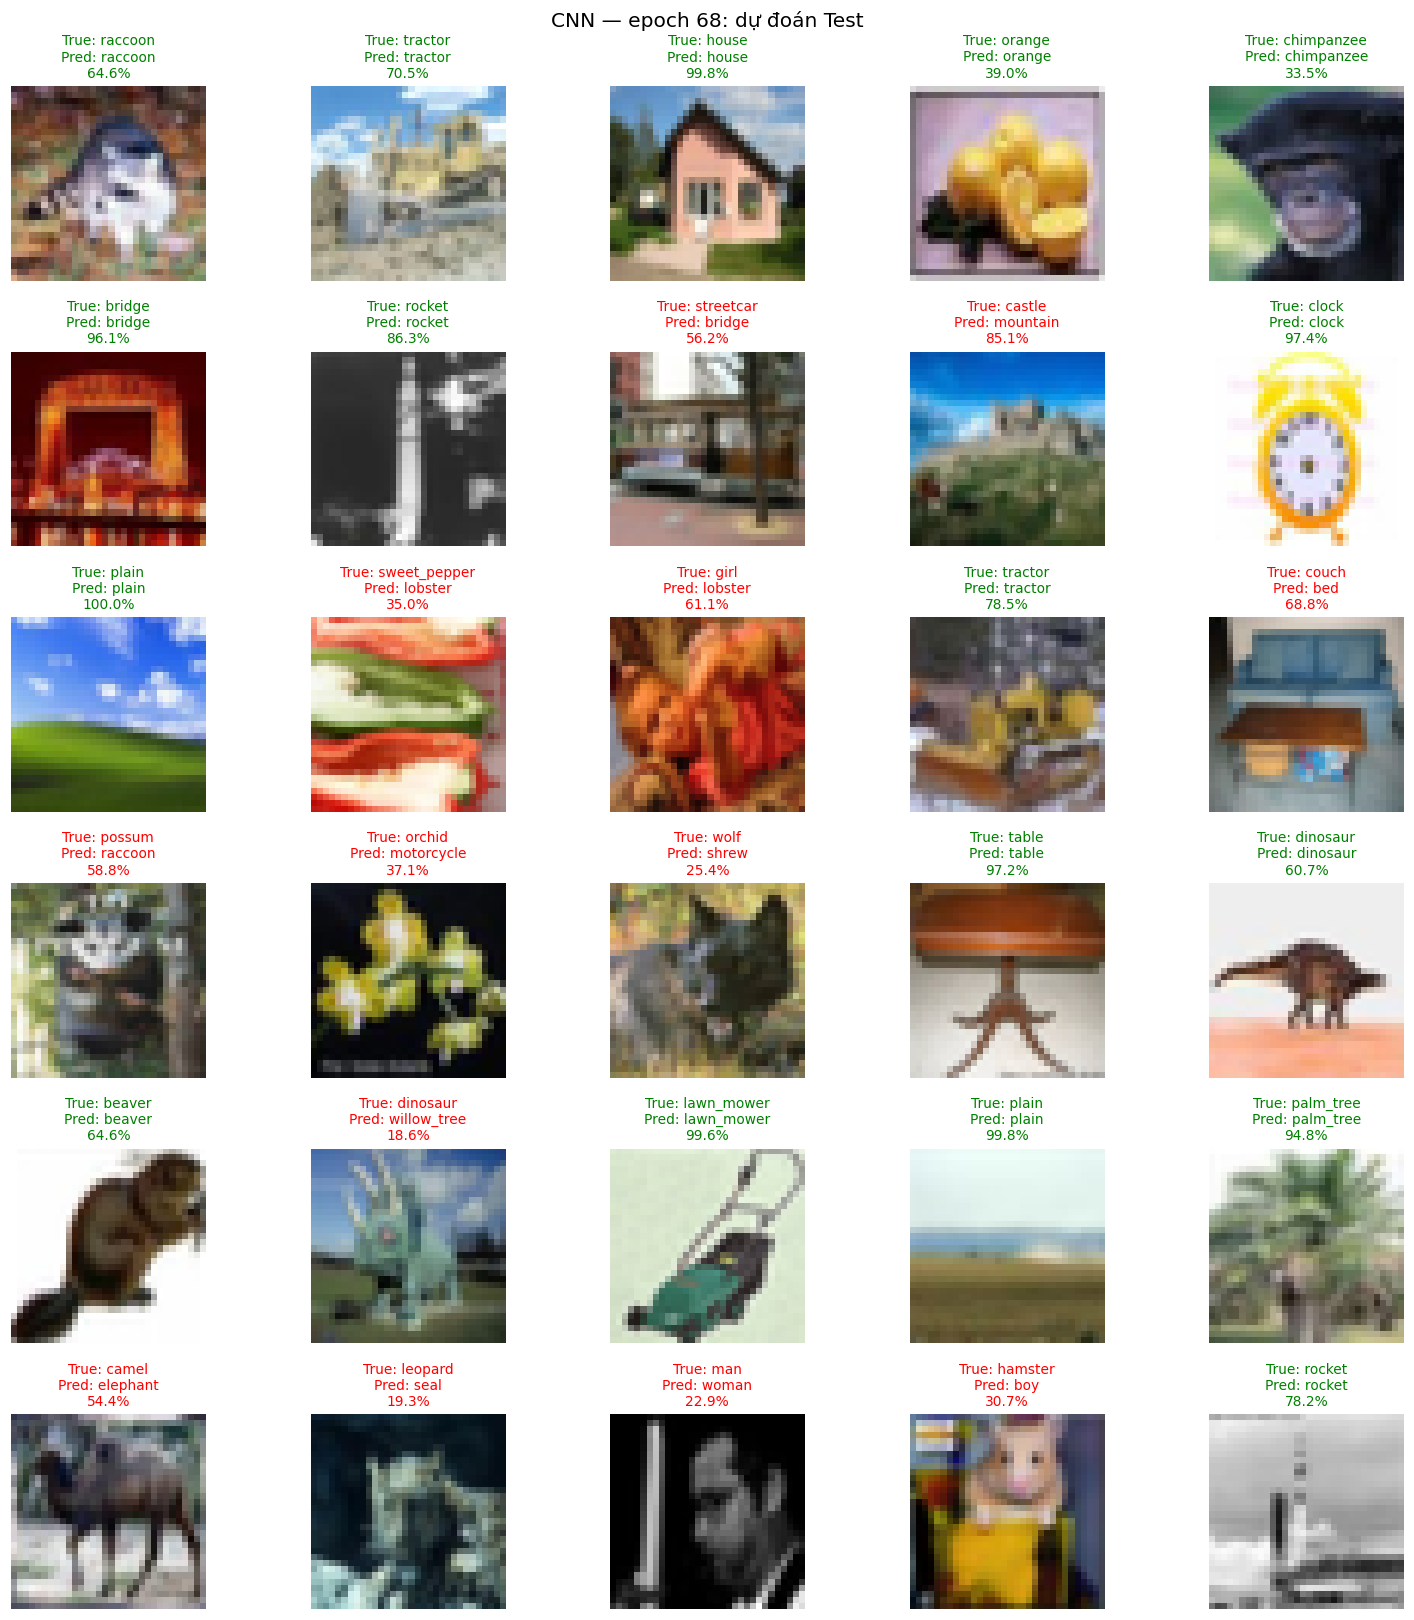

In [50]:
positions = np.asarray(visual_samples["prediction_positions"], dtype=int)
predicted = test_probabilities.argmax(1)
confidence = test_probabilities.max(1)
fig, axes = plt.subplots(6, 5, figsize=(14, 15))

for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i < len(positions):
        p = positions[i]
        ax.imshow(X_test[p])
        ax.set_title(
            f"True: {class_names[Y_test[p]]}\n"
            f"Pred: {class_names[predicted[p]]}\n"
            f"{confidence[p]:.1%}",
            fontsize=9, color="green" if Y_test[p] == predicted[p] else "red"
        )

fig.suptitle(f"CNN — epoch {SELECTED_EPOCH}: dự đoán Test")
fig.tight_layout()
fig.savefig(analysis_dir / "sample_predictions.png", dpi=200)
plt.show()
plt.close(fig)

## 11. Confusion Matrix và Classification Report (100 lớp)


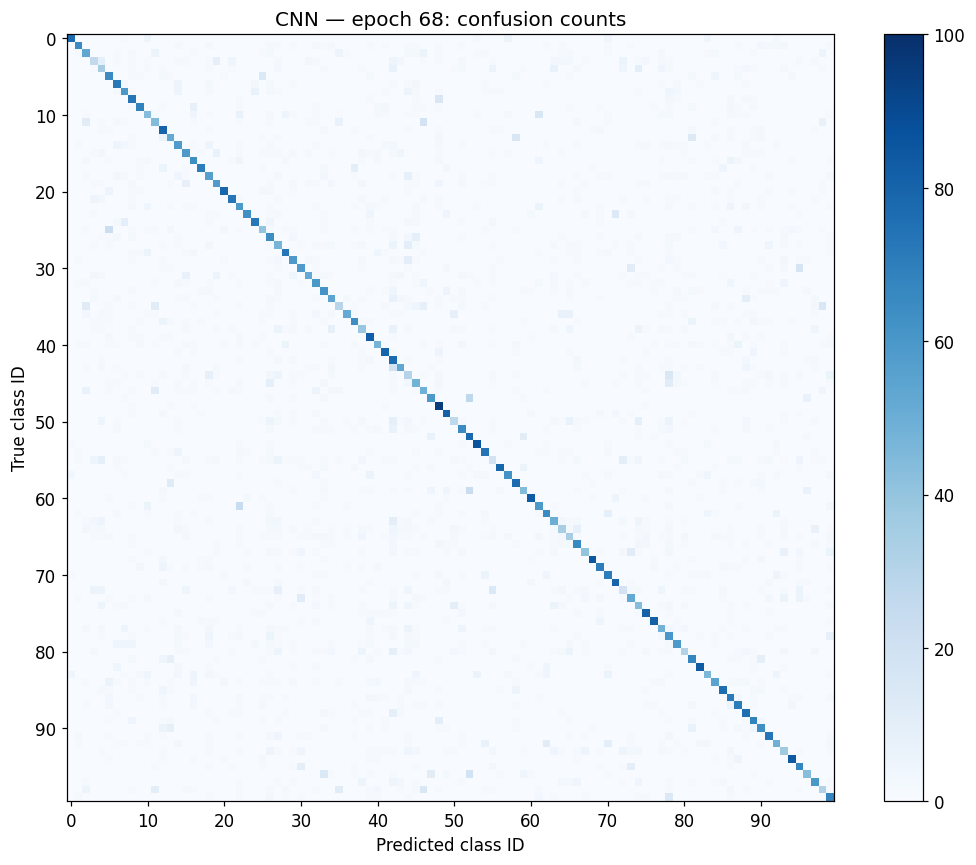

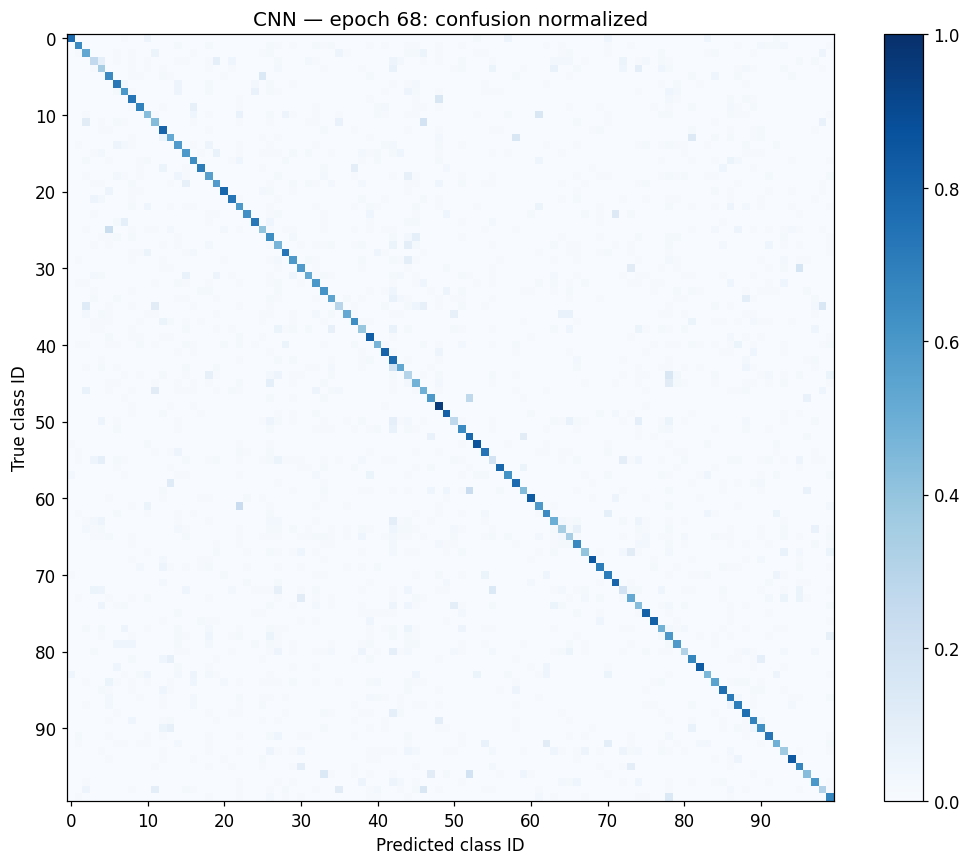

,precision,recall,f1-score,support
macro avg,0.6117,0.5984,0.597,10000.0
weighted avg,0.6117,0.5984,0.597,10000.0


In [51]:
matrix = confusion_matrix(Y_test, predicted, labels=np.arange(len(class_names)))
normalized = np.divide(
    matrix, matrix.sum(1, keepdims=True),
    out=np.zeros_like(matrix, dtype=float),
    where=matrix.sum(1, keepdims=True) != 0
)

for name, values, maximum in [
    ("counts", matrix, int(matrix.sum(1).max())),
    ("normalized", normalized, 1)
]:
    pd.DataFrame(values, index=class_names, columns=class_names).to_csv(
        analysis_dir / f"confusion_{name}.csv"
    )
    fig, ax = plt.subplots(figsize=(10, 8))
    image = ax.imshow(values, cmap="Blues", vmin=0, vmax=maximum)
    ticks = np.arange(0, len(class_names), 10)
    ax.set_xticks(ticks, ticks)
    ax.set_yticks(ticks, ticks)
    ax.set(title=f"CNN — epoch {SELECTED_EPOCH}: confusion {name}",
           xlabel="Predicted class ID", ylabel="True class ID")
    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    fig.savefig(analysis_dir / f"confusion_{name}.png", dpi=200)
    plt.show()
    plt.close(fig)

report = classification_report(
    Y_test, predicted, labels=np.arange(len(class_names)),
    target_names=class_names, output_dict=True, zero_division=0
)
report_table = pd.DataFrame(report).T.drop(index="accuracy", errors="ignore")
report_table.to_csv(analysis_dir / "classification_report.csv")
display(report_table.loc[["macro avg", "weighted avg"]].round(4))

## 12. Tải kết quả từ Kaggle
Các file `.keras`, `.csv`, `.png` nằm trong `/kaggle/working/`. Cell này gộp chúng thành `.zip` để tải cả thư mục dễ hơn.


In [52]:
import shutil
from IPython.display import FileLink, display

for name in (
    "training_curves.png", "history.csv",
    "config.json", "selection.json", "class_names.csv"
):
    source = run_dir / name
    if source.is_file():
        shutil.copy2(source, analysis_dir / name)

zip_path = shutil.make_archive(
    str(run_dir / f"CNN_epoch_{SELECTED_EPOCH:03d}_BaoCao"),
    "zip", str(analysis_dir)
)
display(FileLink(zip_path))

/kaggle/working/cifar100_unified/custom_cnn_20261023T122647Z_069cda/CNN_epoch_068_BaoCao.zip